# Decoding the Surface Code
In this notebook, we introduce two methods of decoding the surface code.  We'll use stim and sinter to make it quick so we can focus on the physics.  We will use the rotated surface code due to its better scaling properties and examine z memory.  For each decoder, we will examine the threshold when the code is subjected to noise.  We need to install packages for the code to run.

In [1]:
%%capture
!pip install stim
!pip install sinter

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import stim
import sinter
import os

We'll begin by creating sinter tasks to sample the code subject to circuit level noise.  To obtain a threshold, we'll sample for several noise values and over several distances.  This is because the threshold separates a decoding phase from a noise dominated phase.  In the decoding phase, the impact of noise decreases as one increases code distance, whereas this is not true for the noisy phase.  Since I happen to know that the threshold for the noise I am examining is about a percent with MWPM (more on this later), I'll design the noise around that.

In [3]:
surface_code_tasks = [
    sinter.Task(
        circuit = stim.Circuit.generated(
            "surface_code:rotated_memory_z",
            rounds=d * 3,
            distance=d,
            after_clifford_depolarization=noise,
            after_reset_flip_probability=noise,
            before_measure_flip_probability=noise,
            before_round_data_depolarization=noise,
        ),
        json_metadata={'d': d, 'r': d * 3, 'p': noise},
    )
    for d in [3, 5, 7]
    for noise in [0.005, 0.006, 0.007, 0.008, 0.009, 0.01, 0.011, 0.012, 0.013, 0.014, 0.015]
]


The above stim circuit creates a noisy rotated surface code with the specified parameters.  rounds is the number of rounds of syndrome extraction.  It is valuable for this to be more than one, since the CNOTs that entangle ancillas are subject to noise and seeing whether or not they change consistently can help rule out the possibilty of a faulty CNOT.  The code distance is the weight of the smallest nontrivial logical operator.  For the surface code, is the length of a direction on a lattice.  We subject the circuit that produces the code to four types of noise:

*   **After Clifford depolarization** injects Pauli errors after Clifford gates are applied with probability $p$.  Each error is equally likely.
*   **After reset flip probability** is the probability that an ancilla is flipped after it resets every round.
*   **Before measure flip probability** is the probabilty that a qubit flips before being measured.
*   **Before round data depolarization** is the probability of single qubit depolarization errors at the beginning of a measurement round.



**Decoding with MWPM (Minimum Weight Perfect Matching)**

We will use a package called pymatching that has an inbuilt MWPM algorithm.  We'll install it and then explain MWPM.

In [4]:
%%capture
!pip install pymatching

In [5]:
import pymatching

To understand MWPM, we need some graph theory.  To establish notation, we will consider a weighted graph $G = (V_G, E_G, W_G)$, where $V_G = \lbrace v_i \rbrace$ are vertices, $E_G = \lbrace e_{ij} \rbrace$ are edges between vertices $i$ and $j$, and $W_G = \lbrace W_e \rbrace$ are weights assigned to the edges.  Some definitions:

*   A *matching* of $G$ is a subset of edges $M \subseteq E_G$ such that for two edges in $M$ do not share a common vertex.  Edges in $M$ do not share endpoints.
*   A matching is *perfect* if every vertex in $V$ is incident to exactly one edge in $M$.
*   The weight of a matching $M$ is simply the sum of weights of the edges in $M$.
*   With the above three definitions in mind, a *minimum weight perfect matching* is exactly what it sounds like.

In textbook QEC, the implementation of MWPM is pretty straightforward.  A perfect matching corresponds to an error configuration.  The weights are the (negative log) probability that an error occurs so a MWPM is simply the most likely error.  One corrects the errors by flipping the bits along the chain predicted by MWPM.  Life is more complicated with our stim/sinter pipeline.  This is the case for at least two good reasons:

1.  To accomodate hardware, QEC codes are prepared by entangling data qubits with ancilla qubits that serve as parity checks.  When noise acts on a circuit that prepares a code, it can lead to faulty ancillas.  We address this by seeing how checks change in time.  If noise that affects ancillas is relatively rare, frequent flips will warn us that the ancillas are not to blame for parity check violations.  To include this, our graph must be embedded in a 3d spacetime.

2.  The error correction scheme described above is slow and prone to noise.

To describe how MWPM acts in our ecosystem, we need to discuss how stim addresses these concerns.  Our hero is the detector error model (DEM).  A DEM is a hypergraph $H$ whose vertices are detector parity checks that determine whether a check has changed in the preceding time interval and whose hyperedges determine which detectors are triggered by a given error mechanism.  The weights on the hyperedges are the probabilities of errors occuring. Since the hyperedges correspond to errors, they contain an additional binary label that informs us whether the error induces a logical error.  Since we set decompose error to true, stim decomposes hyperedges to edges.  This sometimes results in an error that only triggers a single detector, meaning there is no need for an edge.  This is remedied by adding "virtual" vertices so that one can define matchings.  One can assign logical values to a matching adding the tags along the path.  The MWPM simply finds the MWPM of the graph we defined using the detector error model.

It is worth briefly commenting on how errors are actually corrected.  We never pause the processor to manually correct errors due to reason 2.  Instead, we use the classical logical error labels to change basis by adding the result.  We conjugate any Clifford gates appied by the necessary logical operator implied by the logical data.  For non-Clifford gates, one needs to use something akin to magic state teleportation.

In [6]:
collected_surface_code_stats: list[sinter.TaskStats] = sinter.collect(
    num_workers=os.cpu_count(),
    tasks=surface_code_tasks,
    decoders=['pymatching'],
    max_shots=1_000_000,
    max_errors=5_000,
    print_progress=False,
)

We now plot the stats and look for a threshold.

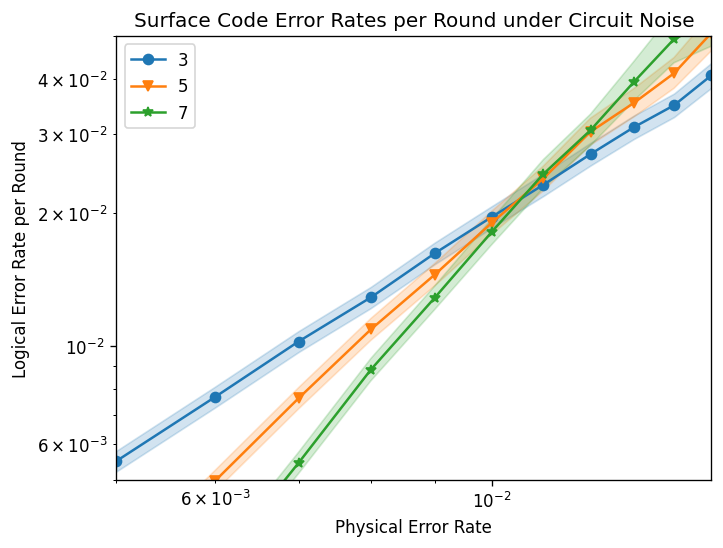

In [7]:
fig, ax = plt.subplots(1, 1)
sinter.plot_error_rate(
    ax=ax,
    stats=collected_surface_code_stats,
    x_func=lambda stat: stat.json_metadata['p'],
    group_func=lambda stat: stat.json_metadata['d'],
    failure_units_per_shot_func=lambda stat: stat.json_metadata['r'],
)
ax.set_ylim(5e-3, 5e-2)
ax.set_xlim(0.005, 0.015)
ax.loglog()
ax.set_title("Surface Code Error Rates per Round under Circuit Noise")
ax.set_xlabel("Physical Error Rate")
ax.set_ylabel("Logical Error Rate per Round")
ax.legend()
fig.set_dpi(120)  # Show it bigger

As stated above, the way to read the above plot is as a competition between the suppression of errors due to code distance and the proliferation of noise targets as we increase code distance.  The threshold is the critical point as larger code distance switches from a boon to a bane.  As suspected, it is about a percent.

**Decoding with Belief Propagation**

We now turn to decoding with belief propagation.  In addition to explaining how beleif propagation works, we will show how to implement it using a custom stim decoder.  We begin by installing the package necessary for a pre-built implementation of belief propagation.

In [8]:
%%capture
!pip install stimbposd

In [9]:
from stimbposd import SinterDecoder_BPOSD

Belief propagation acts on a "detector version" of the usual Tanner graph.  Let's explain the graph in more detail.  The detector error model has a binary $n_{detectors} \times n_{errors}$ matrix $H$ whose $ij$ entry is one if the $i$th detector is violated by the $j$th error mechanism.  The Tanner graph has a vertices $V_T = D \cup E $, where $E$ is the set of errors and $D$ is the set of detectors.   An element  $d_i \in D$ is connected by an edge to an element $e_j \in E$ iff $H_{ij} = 1$.  An error $e$ and its syndrome $s$ are related as usual: $s = He$.  The goal of belief propagation is to calculate probabilities:
$$P(e_i)=\sum_{e_1,...,e_{i-1},e_{i+1},...,e_{n_{errors}}} P(e_1,...,e_{i-1},e_{i+1},...,e_{n_{errors}} \vert s)$$.  The actual belief propagation process occurs in five steps:

1. **Initialization**: Assign to each $e_i \in E$ an initial log-likelihood ratio:
$$l_{ch}(e_i) = log(\frac{P(e_i=0)}{P(e_i=1)}) .$$

2. **Message from errors to detectors**:  Each $e_i$ passes the following message to each connected detector $d_j \in D$.  For $t=1$:
$$ \mu_{i \rightarrow j}^1 = l_{ch}(e_i)$$.
For $t>1$:
$$ \mu_{i\rightarrow j}^t = l_{ch}(e_i) + \sum_{k=1}^{\sigma-1} \mu_{k\rightarrow i}^{t-1},$$
where $\mu_{k\rightarrow i}^{t-1}$ are detector replies from the previous iteration and $\sigma = deg(e_i)$.
3. **Reply from detectors**:  Each $d_j$ replies to the messages it receives from $e_i$ with:
$$ \mu_{j \rightarrow i}^t = (-1)^{s_j} 2 \text{arctanh}[\prod_{k=1}^{\psi-1} \text{tanh}(\mu_{k\rightarrow j}^t)],$$
where $\mu_{k\rightarrow j}^t$ is the message $d_j$ receives from $e_k$ and $\psi = deg(d_j)$.
4. **Log-Likelihood Ratio Update**:  At the end of iteration $t$, update the log-likelihood ratio to
$$l_{ap}^t(e_i) = l_{ch}(e_i) + \sum_{j=1}^\sigma \mu_{j\rightarrow i}^t. $$
5. **Ordered Statistics Decoding(OSD)**:  After a specified number of iterations, standard belief propagation would then make the decision that $e_i=1$ if the total log likelihood is less than zero and and $e_i = 0$ otherwise.  For quantum codes, one incorporates a post-processing procedure called ordered statistics decoding (OSD), which we now outline.  First, one sorts the columns of $H$ by the absolute value of $l$.  Second, we make a "reliable" matrix $B$ by selecting the first $rank(H)$ linearly independent columns of $H$.  Third, we solve a version of the syndrome-error relation.  The solution is $e_B = B^{-1}s$.  Fourth, by appending $e_B$ with zeros, get $e$.  Unpermute the rows.  Finally, we act with the DEMs observable matrix to obtain a prediction about which logical operators are flipped.

In [ ]:
collected_surface_code_stats: list[sinter.TaskStats] = sinter.collect(
    num_workers=os.cpu_count(),
    tasks=surface_code_tasks,
    decoders=['bposd_fast'],
    custom_decoders={
        # Drop OSD order to 0 (Combination Sweep) and switch to fast min_sum
        "bposd_fast": SinterDecoder_BPOSD(
            max_bp_iters=30,      # Cap the failing loops earlier
            osd_order=0,          # 0 is exponentially faster than higher orders
            osd_method="osd_cs",  # Combination Sweep post-processing
            bp_method="min_sum"   # Min-sum is faster than product-sum
        )
    },
    max_shots=50000,
    max_errors=500,
    print_progress=False,
)

Note that above, we customized the BPOSD decoder to lower the run time, since the main point of the present notebook is exposition.  By capping the max interations and restricting to order zero OSD (which is the procedure described above), we keep the runtime to around 20 minutes.  As before, we examine the stats for a threshold.

In [ ]:
fig, ax = plt.subplots(1, 1)
sinter.plot_error_rate(
    ax=ax,
    stats=collected_surface_code_stats,
    x_func=lambda stat: stat.json_metadata['p'],
    group_func=lambda stat: stat.json_metadata['d'],
    failure_units_per_shot_func=lambda stat: stat.json_metadata['r'],
)
ax.set_ylim(5e-3, 5e-2)
ax.set_xlim(0.005, 0.015)
ax.loglog()
ax.set_title("Surface Code Error Rates per Round under Circuit Noise")
ax.set_xlabel("Physical Error Rate")
ax.set_ylabel("Logical Error Rate per Round")
ax.legend()
fig.set_dpi(120)  # Show it bigger

We begin by noting that due to our drastically reduced shot count, the data are appreciably noisier, reflected in the larger error bars.  While the threshold looks lower, the aforementioned noise and the fact that we took fewer shots make a direct comparison difficult.  If one were to compare for small surface codes (such as the instance we examine), the fact that we had to make concessions to runtime for BPOSD is perhaps the most salient point - it is a much slower algorithm for similar looking results.  It is worth noting that BPOSD works for many more codes than MWPM.

**Benchmarking Run Times**

We now provide justification of our claim that BPOSD is apppreciably slower than MWPM.  We will measure the per-shot latency of one round of QEC for each decoder.  To avoid rerunning the above code, we will reimport useful packages.

In [ ]:
%%capture
!pip install stim
!pip install pymatching
!pip install ldpc

In [ ]:
import time
import numpy as np
import stim
import pymatching
import scipy.sparse as sp

try:
    from ldpc import bposd_decoder
except ImportError:
    from ldpc import BpOsdDecoder as bposd_decoder

We begin by defining a helper function to obtain the check and observable matrices from a detector error model.

In [ ]:
def dem_to_matrices(dem: stim.DetectorErrorModel, return_sparse: bool = False):
    """
    Extracts binary parity-check (H_dem) and observable (O_dem) matrices
    along with physical error priors from a stim.DetectorErrorModel.
    """
    num_detectors = dem.num_detectors
    num_observables = dem.num_observables

    h_rows, h_cols = [], []
    o_rows, o_cols = [], []
    priors_list = []
    fault_idx = 0

    for instruction in dem:
        if instruction.type == "error":
            prob = instruction.args_copy()[0]
            targets = instruction.targets_copy()
            priors_list.append(prob)

            for target in targets:
                if target.is_relative_detector_id():
                    h_rows.append(target.val)
                    h_cols.append(fault_idx)
                elif target.is_logical_observable_id():
                    o_rows.append(target.val)
                    o_cols.append(fault_idx)
                elif target.is_separator():
                    continue

            fault_idx += 1

    num_faults = fault_idx
    priors = np.array(priors_list, dtype=np.float64)

    h_data = np.ones(len(h_rows), dtype=np.uint8)
    H_sparse = sp.csc_matrix(
        (h_data, (h_rows, h_cols)),
        shape=(num_detectors, num_faults),
        dtype=np.uint8,
    )
    H_sparse.data %= 2
    H_sparse.eliminate_zeros()

    o_data = np.ones(len(o_rows), dtype=np.uint8)
    O_sparse = sp.csc_matrix(
        (o_data, (o_rows, o_cols)),
        shape=(num_observables, num_faults),
        dtype=np.uint8,
    )
    O_sparse.data %= 2
    O_sparse.eliminate_zeros()

    if return_sparse:
        return H_sparse, O_sparse, priors
    return H_sparse.toarray(), O_sparse.toarray(), priors

We use the helper to incorporate these matrices into a benchmarking function.

In [ ]:
def run_scaling_benchmark(distances=(3, 5, 7), p=0.005, trials=50):
    """
    Profiles per-shot decoding runtime for PyMatching vs. BP-OSD-0
    and formats the resulting metrics into a Markdown slowdown table.
    """
    records = []

    print(f"Running scaling benchmark (p={p}, trials_per_d={trials})...\n")

    for d in distances:
        # 1. Generate Rotated Surface Code Circuit & Extract Spacetime DEM
        circuit = stim.Circuit.generated(
            "surface_code:rotated_memory_x",
            rounds=d,
            distance=d,
            after_clifford_depolarization=p,
            after_reset_flip_probability=p,
            before_measure_flip_probability=p,
            before_round_data_depolarization=p,
        )
        dem = circuit.detector_error_model(decompose_errors=True)

        # 2. Sample realistic defect syndromes (outside timed loops)
        sampler = circuit.compile_detector_sampler()
        defects, _ = sampler.sample(shots=trials, separate_observables=True)

        # ---------------------------------------------------------
        # Benchmark PyMatching (MWPM)
        # ---------------------------------------------------------
        matcher = pymatching.Matching.from_detector_error_model(dem)

        # Warm-up call
        _ = matcher.decode_batch(defects[:1])

        t0 = time.perf_counter()
        _ = matcher.decode_batch(defects)
        t_pm = (time.perf_counter() - t0) / trials

        # ---------------------------------------------------------
        # Benchmark BP-OSD-0
        # ---------------------------------------------------------
        H_dem, O_dem, priors = dem_to_matrices(dem)
        priors_list = priors.tolist()

        try:
            # ldpc v0.1.x uses channel_probs
            bpo = bposd_decoder(
                H_dem,
                channel_probs=priors_list,
                max_iter=d * 2,
                bp_method="ms",
                osd_method="osd0",
                osd_order=0,
            )
        except TypeError:
            try:
                # ldpc v2.x (BpOsdDecoder) uses error_channel
                bpo = bposd_decoder(
                    H_dem,
                    error_channel=priors_list,
                    max_iter=d * 2,
                    bp_method="minimum_sum",
                    osd_method="osd_0",
                    osd_order=0,
                )
            except TypeError:
                # Fallback to scalar error rate if list parsing fails
                bpo = bposd_decoder(
                    H_dem,
                    error_rate=p,
                    max_iter=d * 2,
                    bp_method="ms",
                    osd_method="osd0",
                    osd_order=0,
                )

        # Warm-up call
        bpo.decode(defects[0].astype(np.uint8))
        dec_attr = "osdw_decoding" if hasattr(bpo, "osdw_decoding") else "decoding"
        _ = (O_dem @ getattr(bpo, dec_attr)) % 2

        t0 = time.perf_counter()
        for shot in defects:
            bpo.decode(shot.astype(np.uint8))
            _ = (O_dem @ getattr(bpo, dec_attr)) % 2
        t_bposd = (time.perf_counter() - t0) / trials

        # Store results
        num_detectors = circuit.num_detectors
        num_faults = H_dem.shape[1]
        slowdown = t_bposd / t_pm if t_pm > 0 else 0.0

        records.append({
            "d": d,
            "detectors": num_detectors,
            "faults": num_faults,
            "t_pm_us": t_pm * 1e6,
            "t_bposd_ms": t_bposd * 1e3,
            "slowdown": slowdown,
        })

        print(
            f"d={d:2d} | Detectors: {num_detectors:4d} | Faults: {num_faults:5d} | "
            f"PyMatching: {t_pm*1e6:6.1f} µs | BP-OSD-0: {t_bposd*1e3:6.2f} ms | "
            f"Slowdown: {slowdown:5.0f}x"
        )

    # ---------------------------------------------------------
    # Render Markdown Table
    # ---------------------------------------------------------
    print("\n" + "=" * 70)
    print("SLOWDOWN TABLE")
    print("=" * 70 + "\n")

    md_table = [
        "| Distance ($d$) | Spacetime Detectors ($M$) | Circuit Faults ($N$) | PyMatching (µs/shot) | BP-OSD-0 (ms/shot) | Slowdown Factor |",
        "| :---: | :---: | :---: | :---: | :---: | :---: |",
    ]
    for r in records:
        md_table.append(
            f"| **{r['d']}** | {r['detectors']} | {r['faults']} | "
            f"{r['t_pm_us']:.1f} µs | {r['t_bposd_ms']:.2f} ms | "
            f"**~{r['slowdown']:.0f}×** |"
        )

    output = "\n".join(md_table)
    print(output)
    return records

Let's summarize the above cell.  It iterates the following for each element of a set of distances:
1. Generate a rotated surface code and extract its DEM.
2. Sample defects.
3. Time MWPM
4. Time BPOSD0.  
5. Print. results in atable comparing per shot latency across the spectrum of distances.

Here are the results:

In [ ]:
if __name__ == "__main__":
  run_scaling_benchmark(distances=[3, 5, 7], p=0.005, trials=50)

Might as well present the markdown table in markdown:

**Slowdown Table**

| Distance ($d$) | Spacetime Detectors ($M$) | Circuit Faults ($N$) | PyMatching (µs/shot) | BP-OSD-0 (ms/shot) | Slowdown Factor |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **3** | 24 | 291 | 1.7 µs | 0.14 ms | **~78×** |
| **5** | 120 | 1958 | 7.6 µs | 1.72 ms | **~226×** |
| **7** | 336 | 2377 | 23.9 µs | 3.87 ms | **~162×** |

This confirms what we suspected from running the cells - BPOSD0 is dramatically slower.  Given how similar the threshold look in our plots, if one is deciding which decoder to use for the small surface codes we examine, the blazing speed of MWPM more than compensates for any small threshold advantage BPOSD0 might have.

**Other Resources**

*   For MWPM, we used the code in https://github.com/quantumlib/Stim/blob/main/doc/getting_started.ipynb.
*   2307.14989 has a good discussion of both decoders used here, albiet in a static setting rather than a DEM setting.
*   2211.03288 discusses graph based decoding including in the spacetime picture.
*   2407.13826 has a thorough discussion of DEMs.

